In [43]:
import pandas as pd

df = pd.read_csv("../data/raw_student_performance.csv")


print(
    df.loc[df["age"] < 16, "age"]
      .value_counts()
      .sort_index()
)

age
3.0      26
10.0      3
11.0      6
12.0     23
13.0    102
14.0    346
15.0    925
Name: count, dtype: int64


In [258]:
import pandas as pd

df = pd.read_csv("../data/raw_student_performance.csv")


print(df["age"].describe())

count    100500.000000
mean         20.998000
std           2.533943
min           3.000000
25%          19.000000
50%          21.000000
75%          23.000000
max          32.000000
Name: age, dtype: float64


In [356]:
duplicate_ids = df[
    df["student_id"].duplicated(keep=False)
].sort_values("student_id")

print(duplicate_ids)

       student_id   age         department  level  study_hours  \
946        100087  22.0            Physics    100     2.122790   
57539      100087  22.0            Physics    100     2.122790   
440        100149  22.0  Civil Engineering    200    14.969781   
9176       100149  22.0  Civil Engineering    200    14.969781   
74546      100226  21.0  Civil Engineering    400     3.760647   
...           ...   ...                ...    ...          ...   
92993      199476  17.0     Cyber Security    200     5.813276   
19564      199836  20.0     Cyber Security    300     0.822429   
38866      199836  20.0     Cyber Security    300     0.822429   
99161      199906  23.0  Civil Engineering    400     5.357922   
71115      199906  23.0  Civil Engineering    400     5.357922   

       attendance_rate  previous_gpa  assignment_average  quiz_average  \
946         100.000000      2.754504           72.973568     79.776219   
57539       100.000000      2.754504           72.973568   

In [357]:
duplicate_mask = df.duplicated(keep=False)
print("Duplicate rows:", duplicate_mask.sum())
missing_mask = df.isnull().any(axis=1)
print("Rows with missing values:", missing_mask.sum())
invalid_mask = (
    (df["study_hours"] < 0)
    | (df["attendance_rate"] > 100)
    | (df["previous_gpa"] > 5)
    | (df["age"] < 16)
)
print("Rows with invalid values:", invalid_mask.sum())

print("\nDuplicate + missing:",
      (duplicate_mask & missing_mask).sum())

print("Duplicate + invalid:",
      (duplicate_mask & invalid_mask).sum())

print("Missing + invalid:",
      (missing_mask & invalid_mask).sum())

Duplicate rows: 1000
Rows with missing values: 9645
Rows with invalid values: 1506

Duplicate + missing: 106
Duplicate + invalid: 20
Missing + invalid: 154


In [410]:
duplicated_row=df.duplicated(keep=False)
print("Duplicated_rows: ",duplicated_row.sum())
missing_values=df.isnull().any(axis=1)
print("Missing_values_count: ",missing_values.sum())
invalid_values=(
    (df["age"] < 16)
    | (df["previous_gpa"] > 5)
    | (df["attendance_rate"] > 100)
    | (df["study_hours"]<0)
)                
print("invalid_data: ",invalid_values.sum())

print("\nDuplicated + missing Data: ",(duplicated_row & missing_values).sum())

print("Missing + Invalid Data: ", (missing_values & invalid_values).sum())

print("Invalid + Duplicated: ", (invalid_values & duplicated_row).sum())

Duplicated_rows:  1000
Missing_values_count:  9645
invalid_data:  1506

Duplicated + missing Data:  106
Missing + Invalid Data:  154
Invalid + Duplicated:  20


In [411]:
clean_df = df.drop_duplicates()

print("Before:", len(df))
print("After:", len(clean_df))
print("Removed:", len(df) - len(clean_df))

print("Remaining duplicates:",
      clean_df.duplicated().sum())

print("Unique students:",
      clean_df["student_id"].nunique())

print(clean_df.shape)

Before: 100500
After: 100000
Removed: 500
Remaining duplicates: 0
Unique students: 100000
(100000, 16)


In [ ]:

# Count violations after removing exact duplicates

checks = {
    "Negative study hours": clean_df["study_hours"] < 0,

    "Attendance outside 0–100": (
        (clean_df["attendance_rate"] < 0)
        | (clean_df["attendance_rate"] > 100)
    ),

    "GPA outside 0–5": (
        (clean_df["previous_gpa"] < 0)
        | (clean_df["previous_gpa"] > 5)
    ),

    "Age below 16": clean_df["age"] < 16,
}
#issue is the key and mask is the value
for issue, mask in checks.items():
    print(f"{issue}: {mask.sum():,}")


Negative study hours: 0
Attendance outside 0–100: 0
GPA outside 0–5: 0
Age below 16: 1,422


In [ ]:
for issues,masks in checks.items():
    
    print(f"{issues}: {masks.sum():,}")

Negative study hours: 0
Attendance outside 0–100: 0
GPA outside 0–5: 0
Age below 16: 1,422


In [33]:

import numpy as np
import pandas as pd
df = pd.read_csv("../data/raw_student_performance.csv")


# Start from the deduplicated dataset
clean_df = df.drop_duplicates().copy()

# Record the number of invalid values before correction
invalid_counts_before = {
    "study_hours": (clean_df["study_hours"] < 0).sum(),
    "attendance_rate": (
        (clean_df["attendance_rate"] < 0)
        | (clean_df["attendance_rate"] > 100)
    ).sum(),
    "previous_gpa": (
        (clean_df["previous_gpa"] < 0)
        | (clean_df["previous_gpa"] > 5)
    ).sum(),
}

print("Invalid values before cleaning:")
print(invalid_counts_before)

# Replace invalid values with NaN
clean_df.loc[
    clean_df["study_hours"] < 0,
    "study_hours"
] = np.nan

clean_df.loc[
    ~clean_df["attendance_rate"].between(0, 100),
    "attendance_rate"
] = np.nan

clean_df.loc[
    ~clean_df["previous_gpa"].between(0, 5),
    "previous_gpa"
] = np.nan

print("\nMissing values after correction:")
print(
    clean_df[
        ["study_hours", "attendance_rate", "previous_gpa"]
    ].isna().sum()
)


Invalid values before cleaning:
{'study_hours': np.int64(25), 'attendance_rate': np.int64(25), 'previous_gpa': np.int64(25)}

Missing values after correction:
study_hours        2025
attendance_rate    2025
previous_gpa       2025
dtype: int64


Negative study hours remaining: 25
Attendance outside 0–100 remaining: 25
GPA outside 0–5 remaining: 25

Dataset shape: (100000, 16)


In [56]:

import pandas as pd

df = pd.read_csv("../data/raw_student_performance.csv")
clean_df = df.drop_duplicates().copy()
# Negative study hours, excluding missing values
print(
    "Negative study hours remaining:",
    (clean_df["study_hours"] < 0).sum()
)

# Attendance: present values outside 0–100
attendance_invalid = (
    clean_df["attendance_rate"].notna()
    & ~clean_df["attendance_rate"].between(0, 100)
)

print(
    "Attendance outside 0–100 remaining:",
    attendance_invalid.sum()
)

# GPA: present values outside 0–5
gpa_invalid = (
    clean_df["previous_gpa"].notna()
    & ~clean_df["previous_gpa"].between(0, 5)
)

print(
    "GPA outside 0–5 remaining:",
    gpa_invalid.sum()
)

print("\nDataset shape:", clean_df.shape)


Negative study hours remaining: 25
Attendance outside 0–100 remaining: 25
GPA outside 0–5 remaining: 25

Dataset shape: (100000, 16)


In [57]:

# Count missing values per column
missing_summary = pd.DataFrame({
    "missing_count": clean_df.isna().sum(),
    "missing_percentage": (
        clean_df.isna().mean() * 100
    ).round(2),
})

missing_summary = missing_summary.sort_values(
    "missing_count",
    ascending=False
)

print(missing_summary)


                       missing_count  missing_percentage
assignment_average              2000                 2.0
previous_gpa                    2000                 2.0
attendance_rate                 2000                 2.0
study_hours                     2000                 2.0
quiz_average                    2000                 2.0
level                              0                 0.0
age                                0                 0.0
department                         0                 0.0
student_id                         0                 0.0
midterm_score                      0                 0.0
internet_access                    0                 0.0
library_visits                     0                 0.0
sleep_hours                        0                 0.0
previous_failures                  0                 0.0
extracurricular_hours              0                 0.0
final_score                        0                 0.0


In [58]:

columns_to_inspect = [
    "study_hours",
    "attendance_rate",
    "previous_gpa",
    "assignment_average",
    "quiz_average",
]

print(clean_df[columns_to_inspect].describe().T)

print("\nSkewness:")
print(clean_df[columns_to_inspect].skew().round(3))


                      count       mean        std        min        25%  \
study_hours         98000.0   4.503212   2.580300  -5.000000   2.595830   
attendance_rate     98000.0  77.828327  11.709667  27.820918  69.900800   
previous_gpa        98000.0   2.801733   0.704453   0.000000   2.329116   
assignment_average  98000.0  67.404265  11.448648  17.887189  59.664127   
quiz_average        98000.0  65.143494  13.517399   9.030365  55.998146   

                          50%        75%    max  
study_hours          4.026102   5.900431   15.0  
attendance_rate     78.002560  86.106461  150.0  
previous_gpa         2.802288   3.272029    7.0  
assignment_average  67.397955  75.147675  100.0  
quiz_average        65.122183  74.326789  100.0  

Skewness:
study_hours           1.039
attendance_rate      -0.117
previous_gpa          0.046
assignment_average   -0.006
quiz_average         -0.028
dtype: float64


In [66]:

import numpy as np

# Start from the deduplicated dataset
clean_df = df.drop_duplicates().copy()

# Record the number of invalid values before correction
invalid_counts_before = {
    "study_hours": (clean_df["study_hours"] < 0).sum(),
    "attendance_rate": (
        (clean_df["attendance_rate"] < 0)
        | (clean_df["attendance_rate"] > 100)
    ).sum(),
    "previous_gpa": (
        (clean_df["previous_gpa"] < 0)
        | (clean_df["previous_gpa"] > 5)
    ).sum(),
}

print("Invalid values before cleaning:")
print(invalid_counts_before)

# Replace invalid values with NaN
clean_df.loc[
    clean_df["study_hours"] < 0,
    "study_hours"
] = np.nan

clean_df.loc[
    ~clean_df["attendance_rate"].between(0, 100),
    "attendance_rate"
] = np.nan

clean_df.loc[
    ~clean_df["previous_gpa"].between(0, 5),
    "previous_gpa"
] = np.nan

print("\nMissing values after correction:")
print(
    clean_df[
        ["study_hours", "attendance_rate", "previous_gpa"]
    ].isna().sum()
)


Invalid values before cleaning:
{'study_hours': np.int64(25), 'attendance_rate': np.int64(25), 'previous_gpa': np.int64(25)}

Missing values after correction:
study_hours        2025
attendance_rate    2025
previous_gpa       2025
dtype: int64


In [67]:

print("Negative study hours remaining:",
      (clean_df["study_hours"] < 0).sum())

print("Attendance outside 0–100 remaining:",
      (~clean_df["attendance_rate"].between(0, 100)).sum())

print("GPA outside 0–5 remaining:",
      (~clean_df["previous_gpa"].between(0, 5)).sum())

print("\nDataset shape:", clean_df.shape)


Negative study hours remaining: 0
Attendance outside 0–100 remaining: 2025
GPA outside 0–5 remaining: 2025

Dataset shape: (100000, 16)


In [68]:

# Negative study hours, excluding missing values
print(
    "Negative study hours remaining:",
    (clean_df["study_hours"] < 0).sum()
)

# Attendance: present values outside 0–100
attendance_invalid = (
    clean_df["attendance_rate"].notna()
    & ~clean_df["attendance_rate"].between(0, 100)
)

print(
    "Attendance outside 0–100 remaining:",
    attendance_invalid.sum()
)

# GPA: present values outside 0–5
gpa_invalid = (
    clean_df["previous_gpa"].notna()
    & ~clean_df["previous_gpa"].between(0, 5)
)

print(
    "GPA outside 0–5 remaining:",
    gpa_invalid.sum()
)

print("\nDataset shape:", clean_df.shape)


Negative study hours remaining: 0
Attendance outside 0–100 remaining: 0
GPA outside 0–5 remaining: 0

Dataset shape: (100000, 16)


In [69]:

import pandas as pd
import numpy as np

columns_to_impute = [
    "study_hours",
    "attendance_rate",
    "previous_gpa",
    "assignment_average",
    "quiz_average",
]

# Inspect missing values before imputation
print("Missing values before imputation:")
print(clean_df[columns_to_impute].isna().sum())

# Use medians as our initial exploratory cleaning strategy
medians = clean_df[columns_to_impute].median()
clean_df[columns_to_impute] = clean_df[columns_to_impute].fillna(medians)

# Verify the dataset
print("\nTotal missing values:", clean_df.isna().sum().sum())
print("Duplicate rows:", clean_df.duplicated().sum())
print("Unique student IDs:", clean_df["student_id"].nunique())
print("Dataset shape:", clean_df.shape)


Missing values before imputation:
study_hours           2025
attendance_rate       2025
previous_gpa          2025
assignment_average    2000
quiz_average          2000
dtype: int64

Total missing values: 0
Duplicate rows: 0
Unique student IDs: 100000
Dataset shape: (100000, 16)


Dataset shape: (100000, 16)

Data types:
student_id                 int64
age                      float64
department                   str
level                      int64
study_hours              float64
attendance_rate          float64
previous_gpa             float64
assignment_average       float64
quiz_average             float64
midterm_score            float64
internet_access              str
library_visits             int64
sleep_hours              float64
previous_failures          int64
extracurricular_hours    float64
final_score              float64
dtype: object

Numerical summary:
                          count       mean       std        min        25%  \
student_id             100000.0  149999.50  28867.66  100000.00  124999.75   
age                    100000.0      21.00      2.53       3.00      19.00   
level                  100000.0     279.83    133.79     100.00     200.00   
study_hours            100000.0       4.50      2.55       0.06       2.63   
attenda

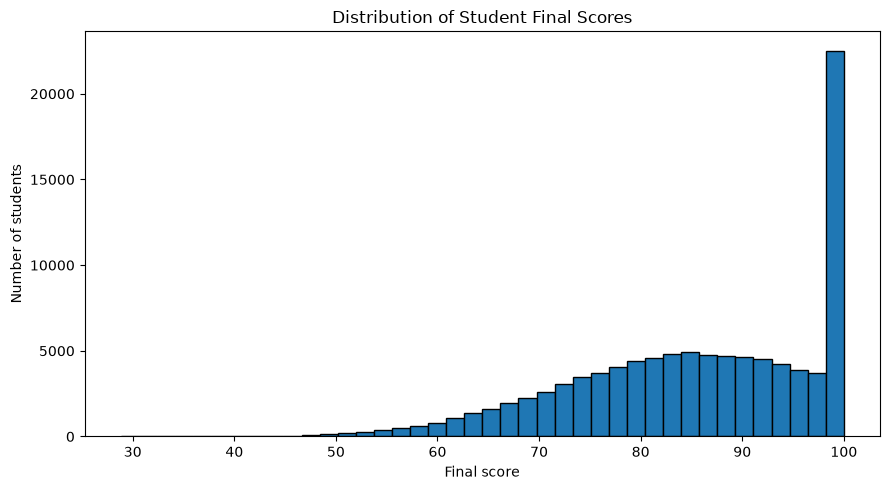


Feature correlations with final_score:
midterm_score            0.566
study_hours              0.503
previous_gpa             0.503
quiz_average             0.375
assignment_average       0.362
attendance_rate          0.119
library_visits           0.067
sleep_hours              0.065
age                     -0.006
level                   -0.008
extracurricular_hours   -0.074
previous_failures       -0.120
Name: final_score, dtype: float64


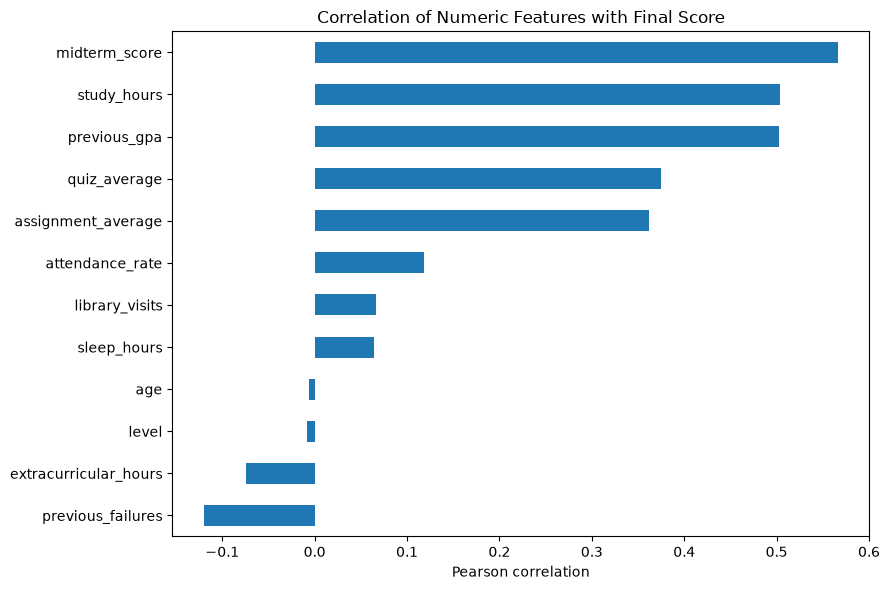

In [71]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Understand dataset structure
print("Dataset shape:", clean_df.shape)
print("\nData types:")
print(clean_df.dtypes)

# 2. Inspect numerical distributions
print("\nNumerical summary:")
print(clean_df.describe().round(2).T)

# 3. Inspect categorical distributions
for column in ["department", "internet_access", "level"]:
    print(f"\n{column} distribution:")
    print(clean_df[column].value_counts())

# 4. Investigate suspicious ages
print("\nAge distribution:")
print(clean_df["age"].describe().round(2))
print("Students aged below 16:", (clean_df["age"] < 16).sum())
print("Students aged 3 or below:", (clean_df["age"] <= 3).sum())

# 5. Examine the target variable
print("\nFinal score distribution:")
print(clean_df["final_score"].describe().round(2))
print("Scores at 0:", (clean_df["final_score"] == 0).sum())
print("Scores at 100:", (clean_df["final_score"] == 100).sum())

# 6. Plot target distribution
plt.figure(figsize=(9, 5))
plt.hist(clean_df["final_score"], bins=40, edgecolor="black")
plt.title("Distribution of Student Final Scores")
plt.xlabel("Final score")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

# 7. Inspect numeric correlations with the target
# Exclude student_id: it is an identifier, not a meaningful measurement.
numeric_features = clean_df.select_dtypes(include=np.number).drop(
    columns=["student_id"], errors="ignore"
)

target_correlations = (
    numeric_features.corr(numeric_only=True)["final_score"]
    .drop("final_score")
    .sort_values(ascending=False)
)

print("\nFeature correlations with final_score:")
print(target_correlations.round(3))

plt.figure(figsize=(9, 6))
target_correlations.sort_values().plot(kind="barh")
plt.title("Correlation of Numeric Features with Final Score")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()


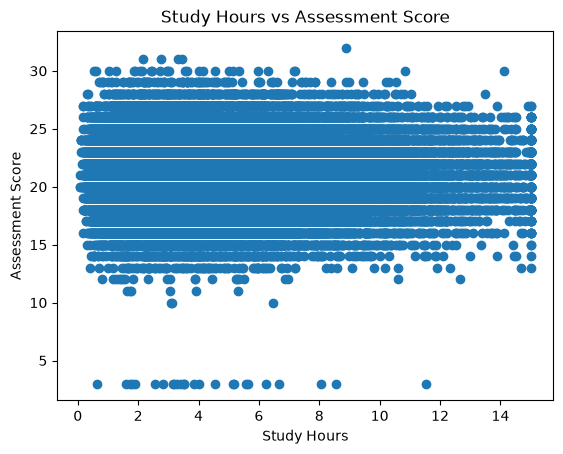

In [86]:
plt.scatter(clean_df["study_hours"], clean_df["age"])

plt.xlabel("Study Hours")
plt.ylabel("Assessment Score")
plt.title("Study Hours vs Assessment Score")

plt.show()